# 01b Genereer kwel input

In dit script wordt de kwel data ingeladen en in het juiste format weggeschreven.

In [1]:
import os
import shutil
from pathlib import Path

import geopandas as gpd
import pandas as pd
from shapely import Polygon, Point
from shapely.geometry import MultiPolygon
import numpy as np
from rasterstats import zonal_stats
from tqdm import tqdm
import matplotlib.pyplot as plt

%matplotlib inline

from hydrolib.dhydamo.core.drr import DRRModel

#### Definieer benodigde functies

In [14]:
def create_polygon_for_cell(x_midpoint : float, y_midpoint : float, cellsize : float) -> Polygon:

    """This function creates a square polygon for a given cell based on its midpoint coordinates and cell size.

    Args:
        x_midpoint (float): The x-coordinate of the cell's midpoint.
        y_midpoint (float): The y-coordinate of the cell's midpoint.
        cellsize (float): The size of the cell.

    Returns:
        Polygon: A polygon representing the cell.
    """

    upper_left_x = x_midpoint - cellsize / 2
    upper_left_y = y_midpoint + cellsize / 2
    upper_right_x = x_midpoint + cellsize / 2
    upper_right_y = y_midpoint + cellsize / 2
    lower_left_x = x_midpoint - cellsize / 2
    lower_left_y = y_midpoint - cellsize / 2
    lower_right_x = x_midpoint + cellsize / 2
    lower_right_y = y_midpoint - cellsize / 2

    return Polygon([
        Point(upper_left_x, upper_left_y),
        Point(upper_right_x, upper_right_y),
        Point(lower_right_x, lower_right_y),
        Point(lower_left_x, lower_left_y),
        Point(upper_left_x, upper_left_y)
    ])

def seepage_from_input(catchments: gpd.GeoDataFrame, seepage_folder : str, start_date : str, end_date : str) -> pd.DataFrame:

    """This function calculates seepage for each catchment based on input raster files.

    Args:
        catchments (gpd.GeoDataFrame): GeoDataFrame containing catchment polygons.
        seepage_folder (str): Path to the folder containing seepage .ASC files.
        start_date (str): The start date for the seepage calculation.
        end_date (str): The end date for the seepage calculation.

    Returns:
        pd.DataFrame: A DataFrame containing seepage values for each catchment over time.
    """

    # list all files in the seepage folder
    file_list = os.listdir(seepage_folder)

    # filter files based on file extension (.ASC)
    file_list = [file for file in file_list if file.endswith(".ASC")]

    # filter files based on start_date and end_date
    start_date_year = pd.to_datetime(start_date).year
    end_date_year = pd.to_datetime(end_date).year
    file_list = [file for file in file_list if str(start_date_year) in file or str(end_date_year) in file]

    # initialize array to store seepage values for each catchment and time step
    times = []
    arr = np.zeros((len(file_list), len(catchments.code)))

    # for each file in the filtered list, rename it, copy it to the renamed folder, read the raster, and calculate zonal statistics
    for ifile, file in tqdm(enumerate(file_list), total=len(file_list), desc="Reading seepage files"):
        # generate the new file name based on the original file name
        file_renamed = file[:10].replace("_", "") + file[10:-8] + "01_MMD.ASC"
        seepage_folder_renamed = Path(seepage_folder).parent / (Path(seepage_folder).name + "_renamed")
        # if the renamed folder exists, remove it to start fresh
        if os.path.exists(seepage_folder_renamed):
            shutil.rmtree(seepage_folder_renamed)
        os.makedirs(seepage_folder_renamed, exist_ok=True)
        shutil.copy2(os.path.join(seepage_folder, file), os.path.join(seepage_folder_renamed, file_renamed))
        # read the raster file using HYDROLIB functionality
        drrmodel = DRRModel()
        array, affine, time = drrmodel.read_raster(os.path.join(seepage_folder_renamed, file_renamed))
        times.append(time)
        # calculate zonal statistics for the catchments
        stats = zonal_stats(catchments, array, affine=affine, stats="mean", all_touched=True)
        arr[ifile, :] = [stat["mean"] for stat in stats]
    
    result = pd.DataFrame(arr, columns=["sep_" + str(cat) for cat in catchments.code])
    result.index = times

    return result

#### Definieer input en output paden, en overige instellingen

In [3]:
main_dir = "D:\\153961_Oude_IJssel"

gebiedsindeling_gpkg = main_dir + "\\WRIJ_RR_Unpaved_methode_02_input//rr_data_scenarios//#RUN#//#SCENARIO#//#SCENARIO#_onderverdeling_hoogmiddellaag.gpkg"
afwateringseenheden_gpkg = r"D:\153961_Oude_IJssel\WRIJ_RR_Unpaved_methode_02_input\basisdata\afwateringseenheden.gpkg"
raster_folder = main_dir + "\\WRIJ_RR_Unpaved_methode_02_input//rr_data_scenarios//seepage//#SCENARIO#//"
output_csv_total = main_dir + "\\WRIJ_RR_Unpaved_methode_02_input//rr_input_scenarios//#RUN#//#SCENARIO#//kwel_per_RR_knoop.csv"

dir_gebied = main_dir + "\\WRIJ_RR_Unpaved_methode_02_input\\rr_input_area_scenario"
output_csv_gebied = dir_gebied + "\\#RUN#\\#GEBIED#\\#SCENARIO#\\seepage.csv"

cellsize = 25 # m, size of each AMGIO grid cell

#### Selecteer voor welke gebieden, scenario’s en periode de seepage moet worden gegenereerd.

De seepage krijgt een waarde per maand.

In [4]:
# selectie_gebied = 0 # Oude IJssel
# selectie_gebied = 1 # West
# selectie_gebied = 2 # Centraal
# selectie_gebied = 3 # Oost

selectie_gebieden = [1, 2, 3]

scenarios = ["REF"] #, "SCEN"]

# SIMULATIES TBV ONDERZOEK INLOOPTIJD ICM INITIËLE GRONDWATERSTAND

# run_name, scenario = "OY_5_kD20_L4_W_InfMax_InitGWS_20140101_20160930_IMPROVED", "REF"
start_date = "2014-01-01"
end_date = "2016-09-30"

# run_name, scenario = "OY_5_kD20_L4_W_InfMax_InitGWS_20130101_20160930_IMPROVED", "REF"
# start_date = "2013-01-01"
# end_date = "2016-09-30"

# run_name, scenario = "OY_5_kD20_L4_W_InfMax_InitGWS_20120401_20160930_IMPROVED", "REF"
# start_date = "2012-04-01"
# end_date = "2016-09-30"

In [5]:
run_names = ["OY_5_kD20_L4_W_InfMax_InitGWS_20140101_20160930_IMPROVED"]

# run_names = ["OY_5_kD20_L4_W_InfMax_InitGWS_20130101_20160930_IMPROVED"]

# run_names = ["OY_5_kD20_L4_W_InfMax_InitGWS_20120401_20160930_IMPROVED"]

In [6]:
date_range_data = pd.date_range(start_date, end_date, freq="MS")

#### Maak vlakken van subgebieden (laag, middel en hoog) en link subgebieden aan afwateringseenheden

REF
OY_5_kD20_L4_W_InfMax_InitGWS_20140101_20160930_IMPROVED


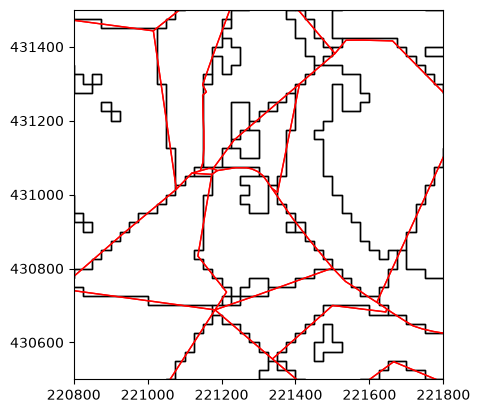

In [8]:
for scenario in scenarios:
    
    print(scenario)
    
    for run in run_names:
        
        print(run)

        # inlezen van geopackage met gebiedsindeling
        gdf = gpd.read_file(gebiedsindeling_gpkg.replace("#SCENARIO#", scenario).replace("#RUN#", run))
        # omzetten van punten naar polygonen met de opgegeven cellsize
        gdf['geometry'] = gdf.apply(lambda row: create_polygon_for_cell(row.geometry.x, row.geometry.y, cellsize), axis=1)
        # GFEIDENT_id updaten met info over de ligging (hoog/middel/laag)
        gdf["GFEIDENT_id"] = gdf.apply(lambda row: f"{row.GFEIDENT_id}_{row.hoog_middel_laag}", axis=1)
        # samenvoegen van cellen met dezelfde GFEIDENT_id tot één subgebied
        gdf_merged = gdf.dissolve(by='GFEIDENT_id')
        # bepalen van de ligging (laag/middel/hoog) van het subgebied
        gdf_merged["ligging"] = gdf_merged.apply(lambda row: "laag" if row.hoog_middel_laag == 1 else ("middel" if row.hoog_middel_laag == 2 else "hoog"), axis=1)

        # specificeren van coördinatenreferentiesysteem voor subgebieden
        gdf_merged = gdf_merged.set_crs("EPSG:28992")
        # inlezen van afwateringseenheden
        gdf_afwateringseenheden = gpd.read_file(afwateringseenheden_gpkg)
        # specificeren van coördinatenreferentiesysteem voor afwateringseenheden
        gdf_afwateringseenheden = gdf_afwateringseenheden.set_crs("EPSG:28992")
        # kopiëren van geometrie naar nieuwe kolom voor latere bewerkingen
        gdf_afwateringseenheden["_right_geometry"] = gdf_afwateringseenheden["geometry"]

        gdf_merged_representative_point = gdf_merged.copy()
        gdf_merged_representative_point["geometry_old"] = gdf_merged_representative_point["geometry"]
        gdf_merged_representative_point["geometry"] = gdf_merged_representative_point.representative_point()

        # uitvoeren van ruimtelijke join tussen subgebieden en afwateringseenheden
        gdf_merged_joined = gdf_merged_representative_point.sjoin(gdf_afwateringseenheden[["GFEIDENT", "_right_geometry", "geometry"]], how="inner", predicate="intersects", rsuffix="_right")
        # # berekenen van de oppervlakte van de intersectie tussen subgebieden en afwateringseenheden
        # gdf_merged_joined["intersection_area"] = gdf_merged_joined.geometry.intersection(gdf_merged_joined["_right_geometry"]).area
        # # toevoegen van unieke identifier voor elke intersectie
        # gdf_merged_joined["GFEIDENT_id"] = gdf_merged_joined.index
        # gdf_merged_joined = gdf_merged_joined.reset_index(drop=True)
        # # selecteren van het afwateringseenheid met de grootste intersectie voor elk subgebied
        # idx = gdf_merged_joined.groupby("GFEIDENT_id")["intersection_area"].idxmax()
        # gdf_merged_joined_selected = gdf_merged_joined.loc[idx]

        # toevoegen van kolom voor subgebied identifier gebaseerd op GFEIDENT en ligging
        gdf_merged_joined["subgebied_id"] = gdf_merged_joined.apply(lambda row: row["GFEIDENT"] + "_" + row["ligging"], axis=1)
        gdf_merged_joined = gdf_merged_joined[["geometry_old", "subgebied_id", "ligging"]]
        gdf_merged_joined = gdf_merged_joined.set_geometry("geometry_old")

        # opslaan van subgebieden naar bestand
        gdf_merged_joined.to_file(main_dir + "\\WRIJ_RR_Unpaved_methode_02_input//rr_data_scenarios//#RUN#//#SCENARIO#//subgebieden.gpkg".replace("#RUN#", run).replace("#SCENARIO#", scenario))

        # plotten van subgebieden en afwateringseenheden
        fig, ax = plt.subplots()
        gdf_merged_joined.plot(ax=ax, facecolor='none', edgecolor='black',legend=True)
        gdf_afwateringseenheden.plot(ax=ax, facecolor='none', edgecolor='red', legend=True)
        ax.set_xlim(220800, 221800)
        ax.set_ylim(430500, 431500)
        plt.show()

#### Inlezen en opwerken van de seepage data

Maandelijkse rasterbestanden met seepage worden ingelezen en samengevoegd tot een tijdserie per subgebied. 

In [15]:
for scenario in scenarios:
    
    print(scenario)
    
    for run in run_names:
        
        print(run)

        # inlezen van subgebieden
        gdf_merged_joined = gpd.read_file(main_dir + "\\WRIJ_RR_Unpaved_methode_02_input//rr_data_scenarios//#RUN#//#SCENARIO#//subgebieden.gpkg".replace("#RUN#", run).replace("#SCENARIO#", scenario))

        # toevoegen van kolom 'code' gebaseerd op subgebied_id
        gdf_merged_joined["code"] = gdf_merged_joined["subgebied_id"]

        # inlezen en opwerken van de seepage data
        df_seepage = seepage_from_input(gdf_merged_joined, r"D:\153961_Oude_IJssel\WRIJ_RR_Unpaved_methode_02_input\rr_data_scenarios\seepage\#SCENARIO#".replace("#SCENARIO#", scenario), start_date, end_date)

        # opslaan van de seepage data
        df_seepage.to_csv(output_csv_total.replace("#RUN#", run).replace("#SCENARIO#", scenario))
            

REF
OY_5_kD20_L4_W_InfMax_InitGWS_20140101_20160930_IMPROVED


Reading seepage files: 100%|██████████| 24/24 [02:58<00:00,  7.42s/it]


In [38]:
for scenario in scenarios:
    
    print(scenario)

    for run in run_names:

        print(run)

        df_seepage_totaal = pd.read_csv(output_csv_total.replace("#RUN#", run).replace("#SCENARIO#", scenario), index_col=0, parse_dates=True)

        for selectie_gebied in selectie_gebieden:
            
            print(selectie_gebied)

            gpkg_unpaved_gebied = dir_gebied + "\\#RUN#\\#GEBIED#\\#SCENARIO#\\gdf_unpaved_winter.gpkg".replace("#RUN#", run).replace("#GEBIED#", f"gebied_{selectie_gebied}").replace("#SCENARIO#", scenario)

            df_unpaved_gebied = gpd.read_file(gpkg_unpaved_gebied.replace("#RUN#", run).replace("#GEBIED#", f"gebied_{selectie_gebied}").replace("#SCENARIO#", scenario))
            subareas_gebied = df_unpaved_gebied.code.tolist()
            subareas_gebied = [f"sep_{code}" for code in subareas_gebied]

            df_seepage = df_seepage_totaal.loc[:, df_seepage_totaal.columns.isin(subareas_gebied)]

            df_seepage.to_csv(output_csv_gebied.replace("#RUN#", run).replace("#GEBIED#", f"gebied_{selectie_gebied}").replace("#SCENARIO#", scenario), index=False)

            # display(df_seepage.head(5))

            print(df_seepage.idxmax().idxmax())

            # print(len(df_seepage.columns))
            # print(len(subareas_gebied))
            # print(set(subareas_gebied) - set(df_seepage.columns))

REF
OY_5_kD20_L4_W_InfMax_InitGWS_20140101_20160930_IMPROVED
1
sep_AE54220027_laag
2
sep_AE54770058_middel
3
sep_AE54740057_laag


In [40]:
df_seepage
# in kaart brengen hoevaak dit voorkomt en wat een goede grens zou zijn
# (df_seepage > 20).sum()

,sep_AE54182820_DE00_middel,sep_AE54182710_DE01_laag,sep_AE54182710_DE01_middel,sep_AE54182710_DE01_hoog,sep_AE54910002_hoog,sep_AE54460027_laag,sep_AE54460027_middel,sep_AE54460026_middel,sep_AE54460017_laag,sep_AE54460017_middel,...,sep_AE54182720_DE00_laag,sep_AE54182720_DE00_middel,sep_AE54182720_DE00_hoog,sep_AE54330033_middel,sep_AE54910079_laag,sep_AE54910079_middel,sep_AE54910079_hoog,sep_AE54380013_laag,sep_AE54380013_middel,sep_AE54980042_laag
2014-01-01,0.038544,3.402823e+38,3.402823e+38,3.402823e+38,0.182805,0.453935,-1.154517,-1.472241,0.506479,-1.076559,...,3.402823e+38,3.402823e+38,3.070433e+38,0.615810,-0.634634,-0.250251,-0.023420,-0.075125,-1.193973,-0.681466
2014-02-01,0.086310,3.402823e+38,3.402823e+38,3.402823e+38,-0.111222,0.276595,-1.229168,-1.196084,0.425042,-1.169742,...,3.402823e+38,3.402823e+38,3.070433e+38,0.398908,-0.552426,-0.427711,-0.460436,-0.145721,-1.278805,-1.071384
2014-03-01,0.161192,3.402823e+38,3.402823e+38,3.402823e+38,-0.583943,-0.034155,-1.469575,-0.939725,0.348025,-1.239883,...,3.402823e+38,3.402823e+38,3.070433e+38,-0.056236,-0.122341,-0.782095,-1.245743,0.492125,-0.605306,-1.667105
2014-04-01,0.126296,3.402823e+38,3.402823e+38,3.402823e+38,-0.861666,-0.200514,-1.134556,-0.441864,-0.081147,-0.915377,...,3.402823e+38,3.402823e+38,3.070433e+38,-0.282833,0.041841,-0.725836,-1.217987,0.302736,-0.213635,-2.379631
2014-05-01,0.029521,3.402823e+38,3.402823e+38,3.402823e+38,-0.732517,-0.249693,-0.031495,0.085790,-0.344243,0.059264,...,3.402823e+38,3.402823e+38,3.070433e+38,-0.152085,-0.483144,-0.302435,-0.582947,-0.287196,0.184181,-0.747643
2014-06-01,0.081574,3.402823e+38,3.402823e+38,3.402823e+38,-0.691626,-0.164580,-0.859429,-0.068353,0.068191,-0.987756,...,3.402823e+38,3.402823e+38,3.070433e+38,-0.157490,0.070605,-0.571001,-0.893050,0.764411,-0.587152,-1.075000
2014-07-01,-0.006424,3.402823e+38,3.402823e+38,3.402823e+38,-0.735911,-0.031221,-0.221100,0.358262,-0.119880,-0.124772,...,3.402823e+38,3.402823e+38,3.070433e+38,-0.136682,-0.161265,-0.560807,-0.797975,-0.094197,-0.132510,-0.197042
2014-08-01,-0.075299,3.402823e+38,3.402823e+38,3.402823e+38,-0.612390,-0.067243,0.039062,1.354634,-0.194110,0.169726,...,3.402823e+38,3.402823e+38,3.070433e+38,-0.276604,-0.497751,-0.224075,-0.305074,-0.266903,0.640417,0.963864
2014-09-01,-0.021846,3.402823e+38,3.402823e+38,3.402823e+38,-0.293038,-0.015570,-0.037362,-0.074277,-0.030085,-0.052407,...,3.402823e+38,3.402823e+38,3.070433e+38,-0.107872,-0.227101,-0.162623,-0.243727,0.446191,-0.602401,-0.450927
2014-10-01,-0.108793,3.402823e+38,3.402823e+38,3.402823e+38,-0.377105,0.027982,0.309155,0.494666,-0.219823,0.300950,...,3.402823e+38,3.402823e+38,3.070433e+38,-0.099359,-0.317022,-0.347857,-0.391391,-0.330993,0.345796,-0.720801


In [41]:
gpkg_unpaved_gebied

'D:\\153961_Oude_IJssel\\WRIJ_RR_Unpaved_methode_02_input\\rr_input_area_scenario\\OY_5_kD20_L4_W_InfMax_InitGWS_20140101_20160930_IMPROVED\\gebied_3\\REF\\gdf_unpaved_winter.gpkg'